# Notebook 04c: SVR on the 68-Feature Dataset (`X_strict`)
**Algorithm:** Support Vector Machine for Regression (SVR)
**Dataset:** `X_strict` (68 features selected by Random Forest)

**Hypothesis:** SVR is highly distance-sensitive. By dropping 64 noisy features identified by Random Forest (a non-linear algorithm), we expect this non-linear dataset to perfectly synergize with our non-linear SVR algorithm, resulting in a cleaner geometric space and a lower MAE.


## 1. Load Data & Imports


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

DATA_DIR = "../../data/final_for_modeling/"
# Load the 150-feature dataset
X_train = pd.read_csv(f"{DATA_DIR}X_train_strict.csv").fillna(0)
X_test = pd.read_csv(f"{DATA_DIR}X_test_strict.csv").fillna(0)

y_train = pd.read_csv(f"{DATA_DIR}y_train.csv").squeeze()
y_test = pd.read_csv(f"{DATA_DIR}y_test.csv").squeeze()

print(f"X_train shape: {X_train.shape} (68 Features)")


X_train shape: (958, 67) (68 Features)


## 2. Train Baseline SVR


In [12]:
svr_baseline = SVR()
svr_baseline.fit(X_train, y_train)
print("Baseline SVR trained successfully.")


Baseline SVR trained successfully.


## 3. Evaluate Baseline & Diagnose Fit


In [13]:
y_train_pred_base = svr_baseline.predict(X_train)
y_test_pred_base  = svr_baseline.predict(X_test)

train_mae_base = mean_absolute_error(y_train, y_train_pred_base)
test_mae_base  = mean_absolute_error(y_test, y_test_pred_base)
train_rmse_base = mean_squared_error(y_train, y_train_pred_base) ** 0.5
test_rmse_base = mean_squared_error(y_test, y_test_pred_base) ** 0.5
train_r2_base  = r2_score(y_train, y_train_pred_base)
test_r2_base   = r2_score(y_test, y_test_pred_base)

pct_err_base = abs(y_test - y_test_pred_base) / y_test
within_10_base = (pct_err_base <= 0.10).mean() * 100

print("=== BASELINE SVR METRICS (150 FEATURES) ===")
print(f"{'Metric':<25} {'Train':>15} {'Test':>15}")
print('-' * 55)
print(f"{'R² Score':<25} {train_r2_base:>15.4f} {test_r2_base:>15.4f}")
print(f"{'RMSE ($)':<25} {train_rmse_base:>15,.2f} {test_rmse_base:>15,.2f}")
print(f"{'MAE ($)':<25} {train_mae_base:>15,.2f} {test_mae_base:>15,.2f}")
print('-' * 55)
print(f"Predictions within 10%: {within_10_base:.1f}%")


=== BASELINE SVR METRICS (150 FEATURES) ===
Metric                              Train            Test
-------------------------------------------------------
R² Score                          -0.0508         -0.0456
RMSE ($)                        72,736.50       65,779.64
MAE ($)                         50,346.52       46,856.47
-------------------------------------------------------
Predictions within 10%: 23.3%


## 4. Baseline Diagnostic Graphs


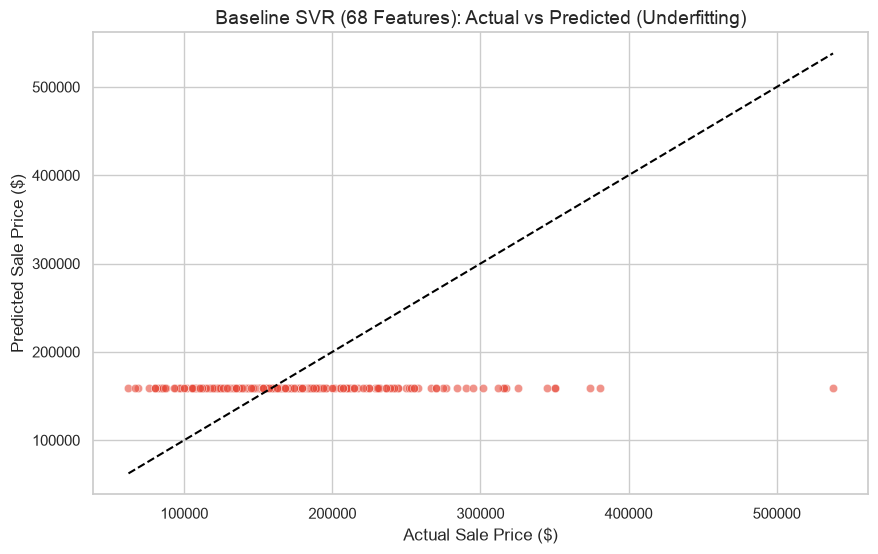

In [14]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_test_pred_base, alpha=0.6, color="#e74c3c")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="black", linestyle="--")
plt.title('Baseline SVR (68 Features): Actual vs Predicted (Underfitting)', fontsize=14)
plt.xlabel('Actual Sale Price ($)')
plt.ylabel('Predicted Sale Price ($)')
plt.show()


## 5. Fine-Tune SVR Hyperparameters (GridSearch)


In [15]:
param_grid = {
    'C': [1000, 10000, 50000],
    'epsilon': [1000, 5000],
    'gamma': ['scale', 'auto']
}

grid_search = GridSearchCV(SVR(kernel='rbf'), param_grid, cv=3, scoring='neg_mean_absolute_error', n_jobs=-1, verbose=1)
print("Starting Grid Search... (This may take a minute)")
grid_search.fit(X_train, y_train)

best_svr = grid_search.best_estimator_
print(f"\nOptimal Hyperparameters Found: {grid_search.best_params_}")


Starting Grid Search... (This may take a minute)
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Optimal Hyperparameters Found: {'C': 50000, 'epsilon': 1000, 'gamma': 'auto'}


## 6. Evaluate Best Model (Untouched Test Set)


In [16]:
y_train_pred_tuned = best_svr.predict(X_train)
y_test_pred_tuned = best_svr.predict(X_test)

train_mae_tuned = mean_absolute_error(y_train, y_train_pred_tuned)
test_mae_tuned = mean_absolute_error(y_test, y_test_pred_tuned)
train_rmse_tuned = mean_squared_error(y_train, y_train_pred_tuned) ** 0.5
test_rmse_tuned = mean_squared_error(y_test, y_test_pred_tuned) ** 0.5
train_r2_tuned = r2_score(y_train, y_train_pred_tuned)
test_r2_tuned = r2_score(y_test, y_test_pred_tuned)

pct_err_tuned = abs(y_test - y_test_pred_tuned) / y_test
within_10_tuned = (pct_err_tuned <= 0.10).mean() * 100

print("=== TUNED SVR METRICS (150 FEATURES) ===")
print(f"{'Metric':<25} {'Train':>15} {'Test':>15}")
print('-' * 55)
print(f"{'R² Score':<25} {train_r2_tuned:>15.4f} {test_r2_tuned:>15.4f}")
print(f"{'RMSE ($)':<25} {train_rmse_tuned:>15,.2f} {test_rmse_tuned:>15,.2f}")
print(f"{'MAE ($)':<25} {train_mae_tuned:>15,.2f} {test_mae_tuned:>15,.2f}")
print('-' * 55)
print(f"Predictions within 10%: {within_10_tuned:.1f}%")


=== TUNED SVR METRICS (150 FEATURES) ===
Metric                              Train            Test
-------------------------------------------------------
R² Score                           0.9058          0.8188
RMSE ($)                        21,778.38       27,384.69
MAE ($)                          5,834.10       14,913.21
-------------------------------------------------------
Predictions within 10%: 73.3%


## 7. Cross-Validation Stability Check


In [17]:
cv_scores_tuned = cross_val_score(best_svr, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
cv_mae_tuned = -cv_scores_tuned

print(f"5-Fold CV MAE Scores: {[f'${val:,.0f}' for val in cv_mae_tuned]}")
print(f"Average CV MAE: ${cv_mae_tuned.mean():,.0f} (± ${cv_mae_tuned.std():,.0f})")


5-Fold CV MAE Scores: ['$15,460', '$15,192', '$15,731', '$17,133', '$18,961']
Average CV MAE: $16,495 (± $1,403)


## 8. Tuned Diagnostic Graphs


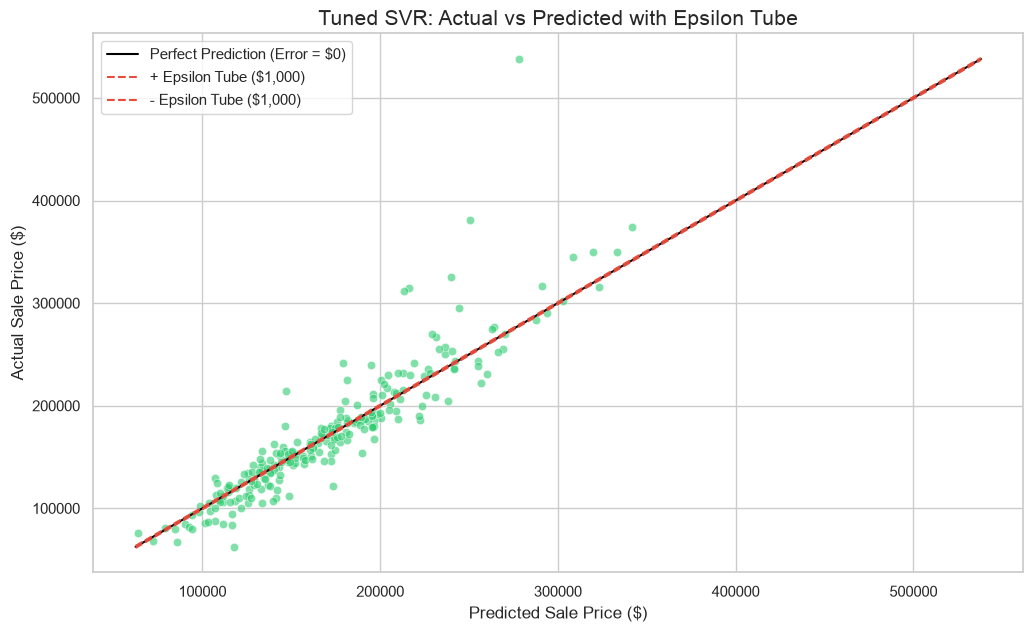

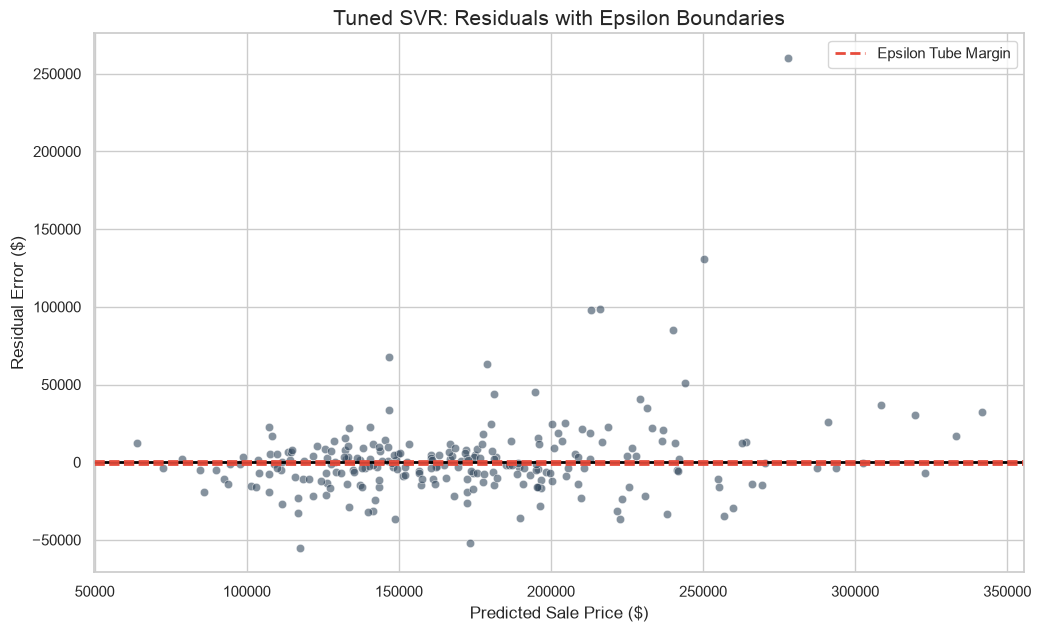

In [18]:
plt.figure(figsize=(12, 7))
sns.scatterplot(x=y_test_pred_tuned, y=y_test, alpha=0.6, color="#2ecc71")

# 1. The Perfect Prediction Line
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="black", linestyle="-", label="Perfect Prediction (Error = $0)")

# 2. The Epsilon Tube
eps = best_svr.epsilon
plt.plot([y_test.min(), y_test.max()], [y_test.min() + eps, y_test.max() + eps], color="#e74c3c", linestyle="--", label=f"+ Epsilon Tube (${eps:,.0f})")
plt.plot([y_test.min(), y_test.max()], [y_test.min() - eps, y_test.max() - eps], color="#e74c3c", linestyle="--", label=f"- Epsilon Tube (${eps:,.0f})")

plt.title('Tuned SVR: Actual vs Predicted with Epsilon Tube', fontsize=15)
plt.xlabel('Predicted Sale Price ($)')
plt.ylabel('Actual Sale Price ($)')
plt.legend()
plt.show()

plt.figure(figsize=(12, 7))
residuals_tuned = y_test - y_test_pred_tuned
sns.scatterplot(x=y_test_pred_tuned, y=residuals_tuned, alpha=0.6, color="#34495e")
plt.axhline(y=0, color="black", linestyle="-", lw=2)
# Show epsilon on residuals too!
plt.axhline(y=eps, color="#e74c3c", linestyle="--", lw=2, label="Epsilon Tube Margin")
plt.axhline(y=-eps, color="#e74c3c", linestyle="--", lw=2)
plt.title('Tuned SVR: Residuals with Epsilon Boundaries', fontsize=15)
plt.xlabel('Predicted Sale Price ($)')
plt.ylabel('Residual Error ($)')
plt.legend()
plt.show()


## 9. Baseline vs Tuned Comparison


In [19]:
comparison_df = pd.DataFrame({
    'Dataset': ['Strict (68)', 'Strict (68)'],
    'Model Phase': ['1. Baseline', '2. Tuned (GridSearch)'],
    'Train MAE': [train_mae_base, train_mae_tuned],
    'Test MAE': [test_mae_base, test_mae_tuned],
    'Train R²': [train_r2_base, train_r2_tuned],
    'Test R²': [test_r2_base, test_r2_tuned],
    'Within 10%': [within_10_base, within_10_tuned]
})

print("=== 68-FEATURE SVR LIFECYCLE COMPARISON ===")
display(comparison_df.round(3))


=== 68-FEATURE SVR LIFECYCLE COMPARISON ===


,Dataset,Model Phase,Train MAE,Test MAE,Train R²,Test R²,Within 10%
0,Strict (68),1. Baseline,50346.523,46856.469,-0.051,-0.046,23.333
1,Strict (68),2. Tuned (GridSearch),5834.104,14913.208,0.906,0.819,73.333


## 10. Save Final Model


In [20]:
import os
os.makedirs('../../models', exist_ok=True)

model_filename = '../../models/svr_68_features_tuned.pkl'
joblib.dump(best_svr, model_filename)

print(f"Champion 68-Feature model successfully saved to: {model_filename}")


Champion 68-Feature model successfully saved to: ../../models/svr_68_features_tuned.pkl
